In [64]:
correlation = np.corrcoef(
    results["resp_signal"],
    stream_resp_realtime
)[0, 1]

print("Respiration correlation:", round(correlation, 4))

Respiration correlation: 0.7751


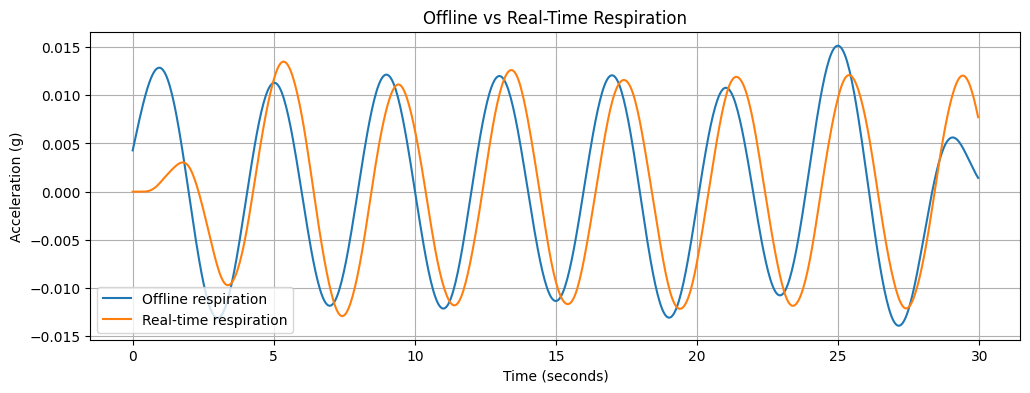

In [63]:
# Compare offline and real-time respiration
plt.figure(figsize=(12, 4))

plt.plot(
    time_resp,
    results["resp_signal"],
    label="Offline respiration"
)

plt.plot(
    time_resp_stream,
    stream_resp_realtime,
    label="Real-time respiration"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Acceleration (g)")
plt.title("Offline vs Real-Time Respiration")
plt.legend()
plt.grid()
plt.show()

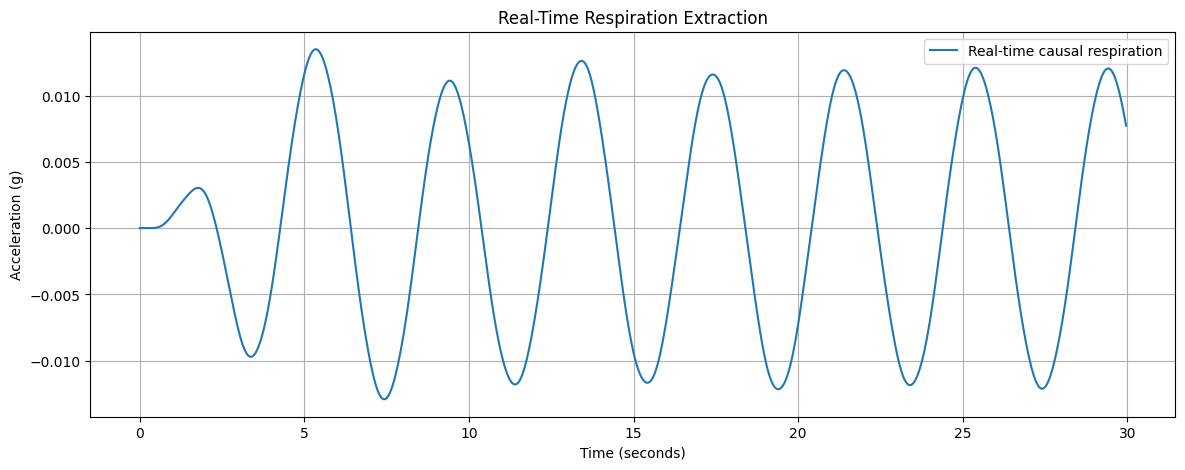

In [62]:
plt.figure(figsize=(14, 5))

plt.plot(
    time_resp_stream,
    stream_resp_realtime,
    label="Real-time causal respiration"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Acceleration (g)")
plt.title("Real-Time Respiration Extraction")
plt.legend()
plt.grid()
plt.show()

In [61]:
block_size = 250

stream_resp_realtime = []

for start in range(0, len(az), block_size):

    block = az[start:start + block_size]

    (
        resp_output,
        decimation_zi,
        resp_zi
    ) = scg_pipeline.process_realtime_respiration_block(
        block,
        decimation_taps,
        decimation_zi,
        resp_sos,
        resp_zi
    )

    stream_resp_realtime.extend(resp_output)

stream_resp_realtime = np.asarray(stream_resp_realtime)

time_resp_stream = np.arange(
    len(stream_resp_realtime)
) / fs_resp

print("Streaming respiration processing completed!")
print("Output samples:", len(stream_resp_realtime))

Streaming respiration processing completed!
Output samples: 750


In [60]:
(
    decimation_taps,
    decimation_zi,
    resp_sos,
    resp_zi,
    fs_resp
) = scg_pipeline.design_realtime_respiration_filters(fs)

print("Original sampling frequency:", fs, "Hz")
print("Respiration sampling frequency:", fs_resp, "Hz")

Original sampling frequency: 249.99999999999977 Hz
Respiration sampling frequency: 24.99999999999998 Hz


In [59]:
import importlib
import scg_pipeline

importlib.reload(scg_pipeline)

<module 'scg_pipeline' from '/Users/tanishkabajpai/SCG-Signal-Processing/src/scg_pipeline.py'>

In [58]:
import importlib
import scg_pipeline

importlib.reload(scg_pipeline)

print(hasattr(
    scg_pipeline,
    "process_realtime_respiration_block"
))

True


In [57]:
block_size = 250

stream_resp_realtime = []

for start in range(0, len(az), block_size):

    block = az[start:start + block_size]

    (
        resp_output,
        decimation_zi,
        resp_zi
    ) = scg_pipeline.process_realtime_respiration_block(
        block,
        decimation_taps,
        decimation_zi,
        resp_sos,
        resp_zi
    )

    stream_resp_realtime.extend(resp_output)

stream_resp_realtime = np.asarray(stream_resp_realtime)

time_resp_stream = np.arange(
    len(stream_resp_realtime)
) / fs_resp

print("Streaming respiration processing completed!")
print("Output samples:", len(stream_resp_realtime))

AttributeError: module 'scg_pipeline' has no attribute 'process_realtime_respiration_block'

In [54]:
(
    decimation_taps,
    decimation_zi,
    resp_sos,
    resp_zi,
    fs_resp
) = scg_pipeline.design_realtime_respiration_filters(fs)

print("Original sampling frequency:", fs, "Hz")
print("Respiration sampling frequency:", fs_resp, "Hz")

Original sampling frequency: 249.99999999999977 Hz
Respiration sampling frequency: 24.99999999999998 Hz


In [53]:
import importlib
import scg_pipeline

importlib.reload(scg_pipeline)

<module 'scg_pipeline' from '/Users/tanishkabajpai/SCG-Signal-Processing/src/scg_pipeline.py'>

In [52]:

def process_realtime_respiration_block(
    az_block,
    decimation_taps,
    decimation_zi,
    resp_sos,
    resp_zi
):

    # Apply causal anti-aliasing FIR filter
    filtered_block, decimation_zi = signal.lfilter(
        decimation_taps,
        [1.0],
        az_block,
        zi=decimation_zi
    )

    # Decimate by 10
    decimated_block = filtered_block[::10]

    # Apply causal respiration IIR filter
    resp_output, resp_zi = signal.sosfilt(
        resp_sos,
        decimated_block,
        zi=resp_zi
    )

    return (
        resp_output,
        decimation_zi,
        resp_zi
    )


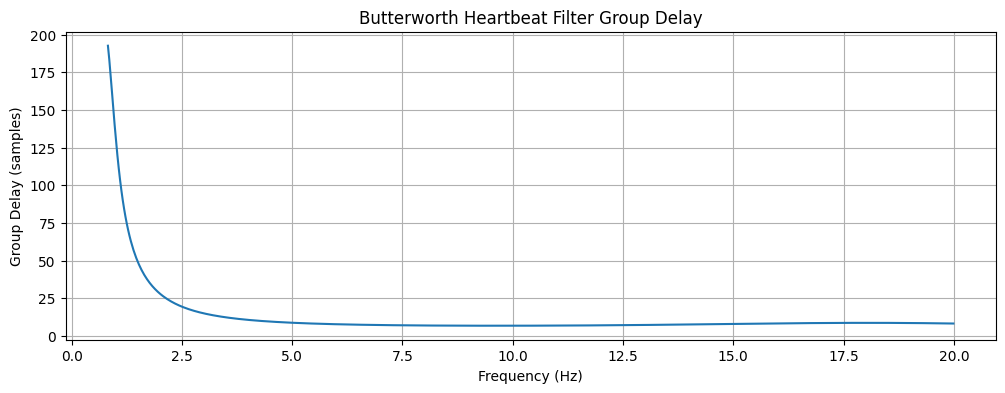

In [51]:
# Calculate frequency response
frequencies, response = signal.sosfreqz(
    heart_sos,
    worN=4096,
    fs=fs
)

# Unwrap phase
phase = np.unwrap(np.angle(response))

# Calculate group delay in samples
group_delay = -np.gradient(phase, frequencies) * fs / (2 * np.pi)

# Restrict to heartbeat passband
mask = (frequencies >= 0.8) & (frequencies <= 20)

# Plot group delay
plt.figure(figsize=(12, 4))

plt.plot(frequencies[mask], group_delay[mask])

plt.xlabel("Frequency (Hz)")
plt.ylabel("Group Delay (samples)")
plt.title("Butterworth Heartbeat Filter Group Delay")
plt.grid()
plt.show()

In [50]:
# Convert sampling frequency into integer sample indices
start = int(2 * fs)
end = int(len(offline_heart) - 2 * fs)

# Extract middle section
offline_segment = offline_heart[start:end].copy()
causal_segment = stream_heart[start:end].copy()

# Remove mean
offline_segment -= np.mean(offline_segment)
causal_segment -= np.mean(causal_segment)

# Calculate cross-correlation
correlation_values = signal.correlate(
    causal_segment,
    offline_segment,
    mode="full"
)

lags = signal.correlation_lags(
    len(causal_segment),
    len(offline_segment),
    mode="full"
)

# Find maximum correlation
best_lag = lags[np.argmax(correlation_values)]

# Convert lag into seconds
time_shift = best_lag / fs

print("Estimated relative time shift:", round(time_shift, 4), "seconds")
print("Estimated relative shift:", best_lag, "samples")

Estimated relative time shift: -0.232 seconds
Estimated relative shift: -58 samples


In [48]:
# Calculate correlation
correlation = np.corrcoef(
    offline_heart,
    stream_heart
)[0, 1]

# Calculate root mean square difference
rmse = np.sqrt(
    np.mean((offline_heart - stream_heart) ** 2)
)

print("Correlation:", round(correlation, 4))
print("RMSE:", round(rmse, 6), "g")

Correlation: -0.0463
RMSE: 0.004419 g


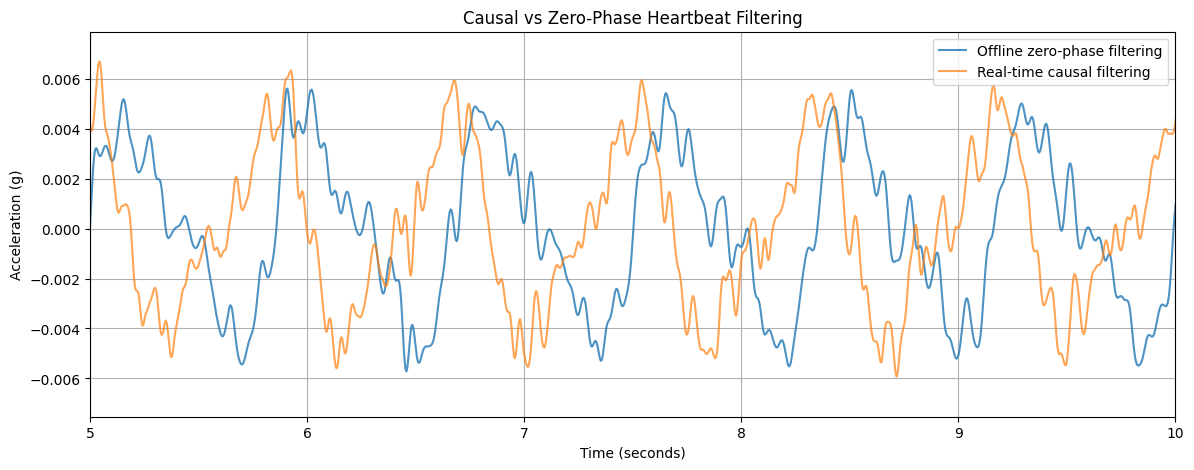

In [47]:
# Offline zero-phase filtering
offline_heart = signal.sosfiltfilt(
    heart_sos,
    az
)

# Compare both filtering methods
plt.figure(figsize=(14, 5))

plt.plot(
    time,
    offline_heart,
    label="Offline zero-phase filtering",
    alpha=0.8
)

plt.plot(
    time,
    stream_heart,
    label="Real-time causal filtering",
    alpha=0.7
)

plt.xlim(5, 10)
plt.xlabel("Time (seconds)")
plt.ylabel("Acceleration (g)")
plt.title("Causal vs Zero-Phase Heartbeat Filtering")
plt.legend()
plt.grid()
plt.show()

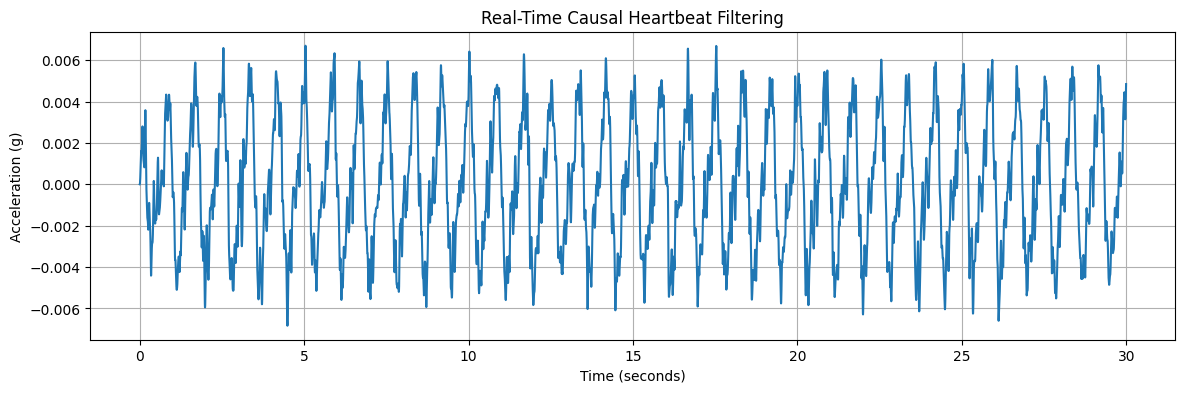

In [46]:
plt.figure(figsize=(14, 4))

plt.plot(time, stream_heart)

plt.xlabel("Time (seconds)")
plt.ylabel("Acceleration (g)")
plt.title("Real-Time Causal Heartbeat Filtering")
plt.grid()
plt.show()

In [45]:
import importlib
import scg_pipeline

importlib.reload(scg_pipeline)

# Design real-time filters
heart_sos, resp_sos, heart_zi, resp_zi = (
    scg_pipeline.design_realtime_filters(fs)
)

# Prepare streaming data
block_size = 250

stream_heart = []
stream_resp = []

# Process recording in blocks
for start in range(0, len(az), block_size):

    block = az[start:start + block_size]

    (
        heart_output,
        resp_output,
        heart_zi,
        resp_zi
    ) = scg_pipeline.process_stream_block(
        block,
        heart_sos,
        resp_sos,
        heart_zi,
        resp_zi
    )

    stream_heart.extend(heart_output)
    stream_resp.extend(resp_output)

# Convert outputs into NumPy arrays
stream_heart = np.asarray(stream_heart)
stream_resp = np.asarray(stream_resp)

print("Streaming processing completed!")
print("Heartbeat samples:", len(stream_heart))
print("Respiration samples:", len(stream_resp))

Streaming processing completed!
Heartbeat samples: 7500
Respiration samples: 7500


In [44]:
import importlib
import scg_pipeline

importlib.reload(scg_pipeline)

# Generate report
report = scg_pipeline.create_recording_report(results)

# Display report
display(report.round(3))

# Save report
report.to_csv(
    project_root / "data" / "processed" / "sample_scg_full_report.csv",
    index=False
)

print("Full recording report saved successfully!")

,duration_s,sampling_frequency_hz,sampling_jitter_percent,signal_std,signal_rms,peak_to_peak,quality_status,heart_rate_bpm,respiration_rate_bpm
0,29.996,250.0,0.0,0.009,0.009,0.041,REQUIRES FURTHER VALIDATION,73.714,15.0


Full recording report saved successfully!


In [43]:
print(results["quality"])

{'duration_s': np.float64(29.996), 'sampling_frequency_hz': np.float64(249.99999999999977), 'sampling_jitter_percent': np.float64(3.1278024069158623e-11), 'signal_mean': np.float64(9.746277858842708e-17), 'signal_std': np.float64(0.00911739035289098), 'signal_rms': np.float64(0.00911739035289098), 'peak_to_peak': np.float64(0.04083251953125), 'finite_values': np.True_, 'quality_status': 'REQUIRES FURTHER VALIDATION'}


In [42]:
import importlib
import scg_pipeline

importlib.reload(scg_pipeline)

results = scg_pipeline.process_scg_recording(csv_path)


SIGNAL QUALITY REPORT
---------------------
duration_s: 29.996
sampling_frequency_hz: 249.99999999999977
sampling_jitter_percent: 3.1278024069158623e-11
signal_mean: 9.746277858842708e-17
signal_std: 0.00911739035289098
signal_rms: 0.00911739035289098
peak_to_peak: 0.04083251953125
finite_values: True
quality_status: REQUIRES FURTHER VALIDATION

SCG PROCESSING RESULTS
----------------------
Heart Rate: 73.71 BPM
Respiration Rate: 15.0 breaths/min


In [41]:
import importlib
import scg_pipeline

importlib.reload(scg_pipeline)

quality = scg_pipeline.assess_signal_quality(
    time,
    az,
    fs
)

print(quality)

{'duration_s': np.float64(29.996), 'sampling_frequency_hz': np.float64(249.99999999999977), 'sampling_jitter_percent': np.float64(3.1278024069158623e-11), 'signal_mean': np.float64(9.746277858842708e-17), 'signal_std': np.float64(0.00911739035289098), 'signal_rms': np.float64(0.00911739035289098), 'peak_to_peak': np.float64(0.04083251953125), 'finite_values': np.True_, 'quality_status': 'REQUIRES FURTHER VALIDATION'}


In [40]:
import importlib
import scg_pipeline

importlib.reload(scg_pipeline)

# Load the recording
time, fs, ax, ay, az = scg_pipeline.load_scg_data(csv_path)

# Assess signal quality
quality = scg_pipeline.assess_signal_quality(
    time,
    az,
    fs
)

# Display results
for parameter, value in quality.items():
    print(f"{parameter}: {value}")

duration_s: 29.996
sampling_frequency_hz: 249.99999999999977
sampling_jitter_percent: 3.1278024069158623e-11
signal_mean: 9.746277858842708e-17
signal_std: 0.00911739035289098
signal_rms: 0.00911739035289098
peak_to_peak: 0.04083251953125
finite_values: True
quality_status: REQUIRES FURTHER VALIDATION


In [38]:
import importlib
import scg_pipeline

importlib.reload(scg_pipeline)

scg_pipeline.save_scg_results(
    results,
    project_root / "data" / "processed",
    recording_name="sample_scg"
)

Results saved successfully!
Output folder: /Users/tanishkabajpai/SCG-Signal-Processing/data/processed


In [37]:
import importlib
import scg_pipeline

importlib.reload(scg_pipeline)

scg_pipeline.save_scg_results(
    results,
    project_root / "data" / "processed"
)

Results saved to: /Users/tanishkabajpai/SCG-Signal-Processing/data/processed


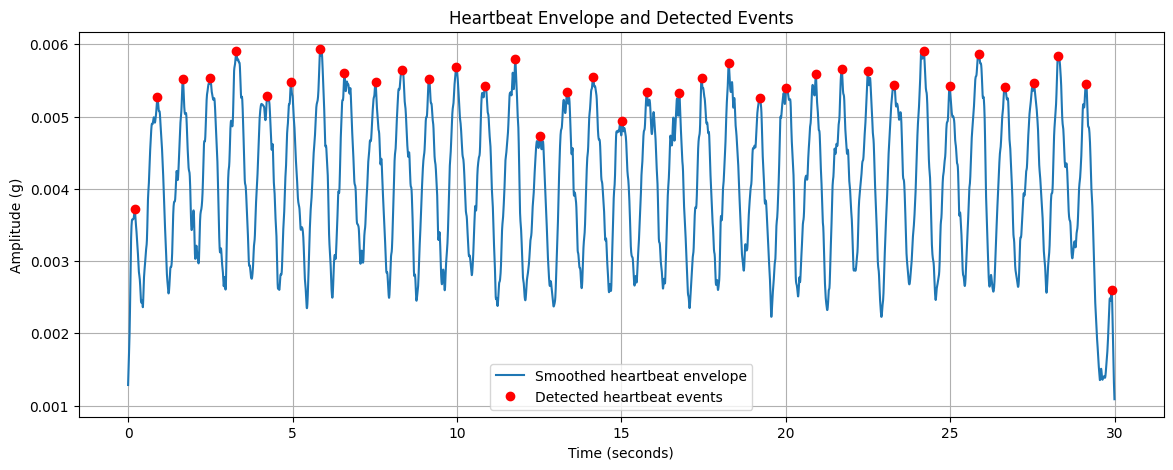

In [36]:
plt.figure(figsize=(14, 5))

plt.plot(
    results["time"],
    results["heart_envelope"],
    label="Smoothed heartbeat envelope"
)

plt.plot(
    results["time"][results["heart_peaks"]],
    results["heart_envelope"][results["heart_peaks"]],
    "ro",
    label="Detected heartbeat events"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (g)")
plt.title("Heartbeat Envelope and Detected Events")
plt.legend()
plt.grid()
plt.show()

In [35]:
print(results.keys())

dict_keys(['heart_rate', 'respiration_rate', 'heart_signal', 'heart_envelope', 'resp_signal', 'heart_peaks', 'resp_peaks', 'time'])


In [34]:
import importlib
import scg_pipeline

importlib.reload(scg_pipeline)

results = scg_pipeline.process_scg_recording(csv_path)


SCG PROCESSING RESULTS
----------------------
Sampling frequency: 250.0 Hz
Heart Rate: 73.71 BPM
Respiration Rate: 15.0 breaths/min


In [33]:
# Heartbeat envelope with detected events

plt.figure(figsize=(14, 5))

plt.plot(
    results["time"],
    results["heart_envelope"],
    label="Smoothed heartbeat envelope"
)

plt.plot(
    results["time"][results["heart_peaks"]],
    results["heart_envelope"][results["heart_peaks"]],
    "ro",
    label="Detected heartbeat events"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (g)")
plt.title("Heartbeat Envelope and Detected Events")
plt.legend()
plt.grid()
plt.show()

KeyError: 'heart_envelope'

<Figure size 1400x500 with 0 Axes>

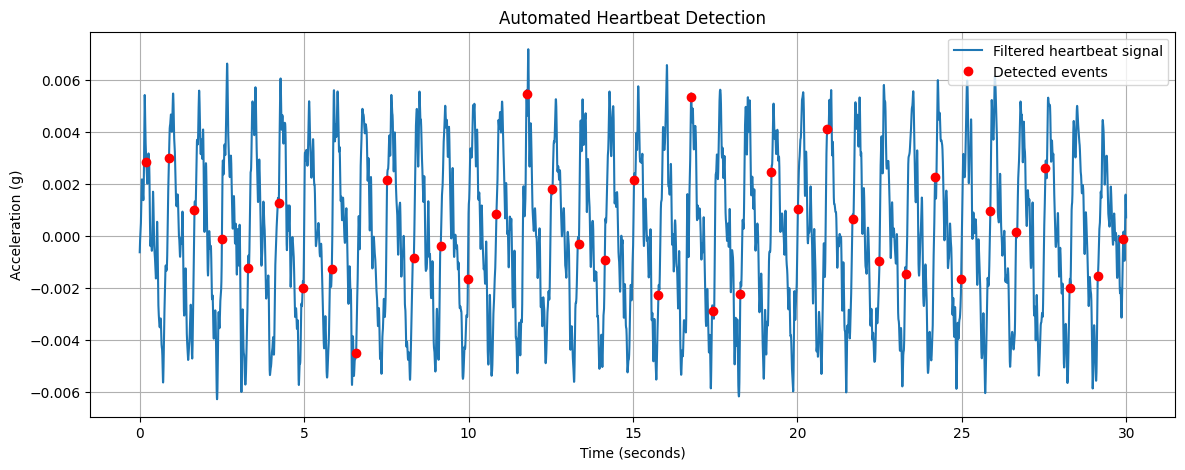

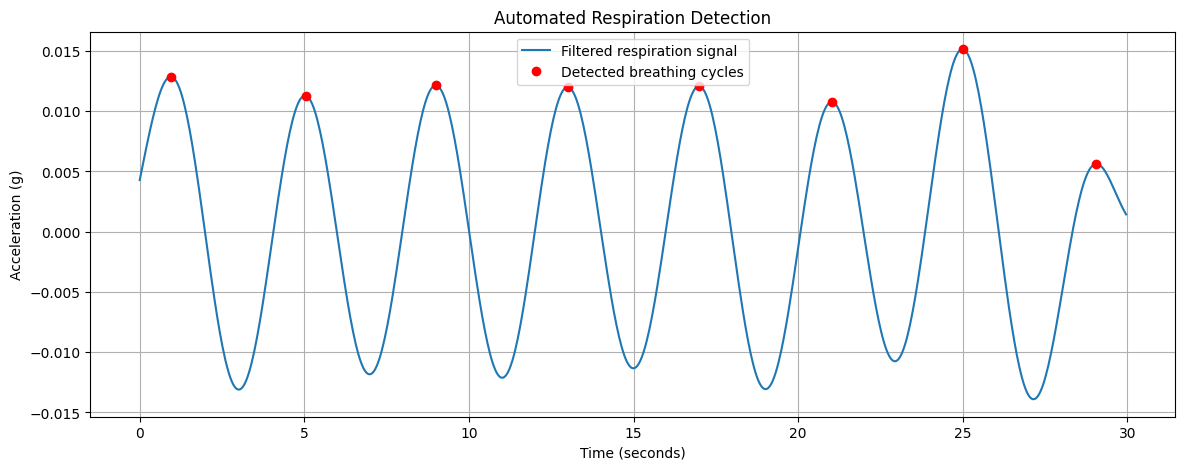

In [32]:
# Heartbeat detection plot
heart_time = results["time"]
heart_peaks = results["heart_peaks"]

plt.figure(figsize=(14, 5))

plt.plot(
    heart_time,
    results["heart_signal"],
    label="Filtered heartbeat signal"
)

plt.plot(
    heart_time[heart_peaks],
    results["heart_signal"][heart_peaks],
    "ro",
    label="Detected events"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Acceleration (g)")
plt.title("Automated Heartbeat Detection")
plt.legend()
plt.grid()
plt.show()


# Respiration detection plot
resp_time = np.arange(len(results["resp_signal"])) / 25
resp_peaks = results["resp_peaks"]

plt.figure(figsize=(14, 5))

plt.plot(
    resp_time,
    results["resp_signal"],
    label="Filtered respiration signal"
)

plt.plot(
    resp_time[resp_peaks],
    results["resp_signal"][resp_peaks],
    "ro",
    label="Detected breathing cycles"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Acceleration (g)")
plt.title("Automated Respiration Detection")
plt.legend()
plt.grid()
plt.show()

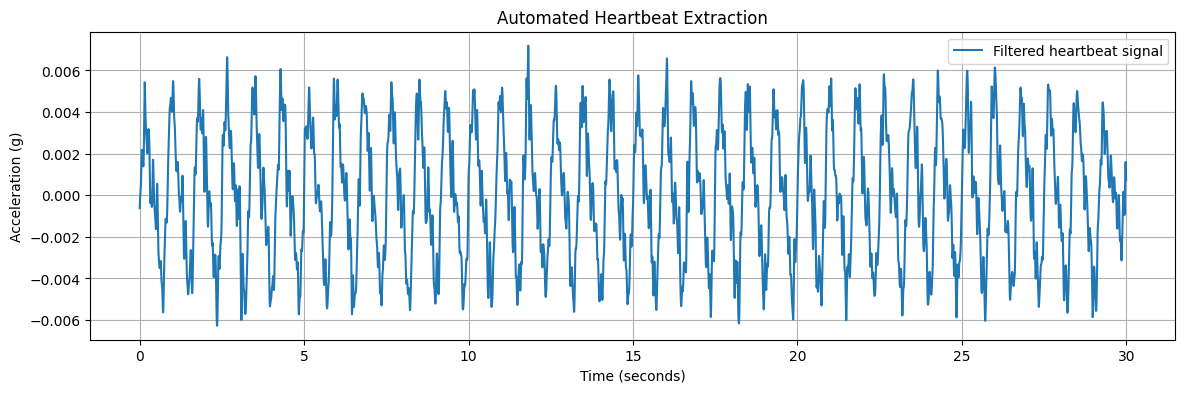

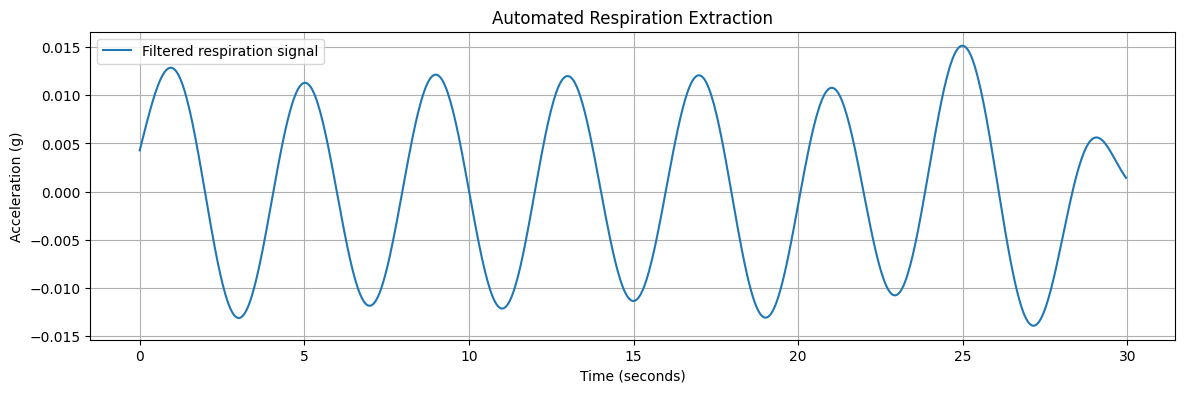

In [ ]:
# Heartbeat plot
plt.figure(figsize=(14, 4))

plt.plot(
    results["time"],
    results["heart_signal"],
    label="Filtered heartbeat signal"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Acceleration (g)")
plt.title("Automated Heartbeat Extraction")
plt.legend()
plt.grid()
plt.show()


# Respiration plot
time_resp = np.arange(len(results["resp_signal"])) / (250 / 10)

plt.figure(figsize=(14, 4))

plt.plot(
    time_resp,
    results["resp_signal"],
    label="Filtered respiration signal"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Acceleration (g)")
plt.title("Automated Respiration Extraction")
plt.legend()
plt.grid()
plt.show()

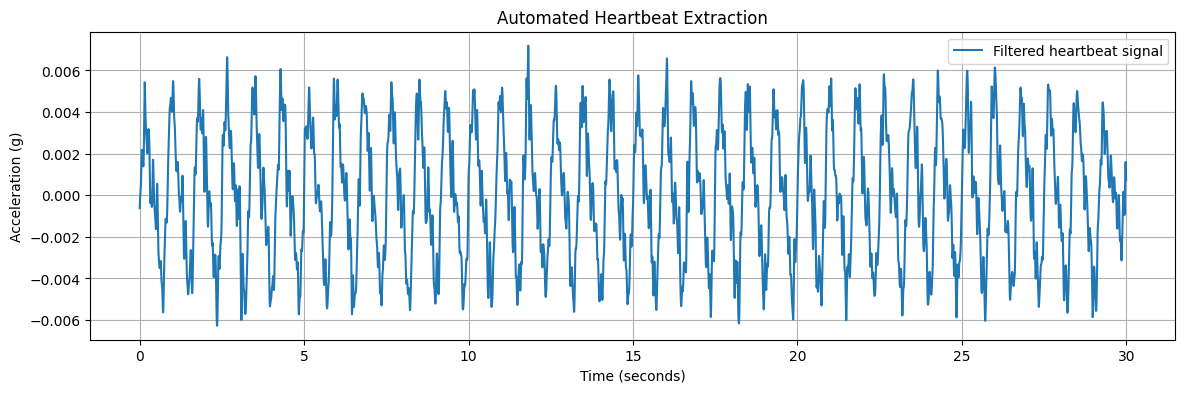

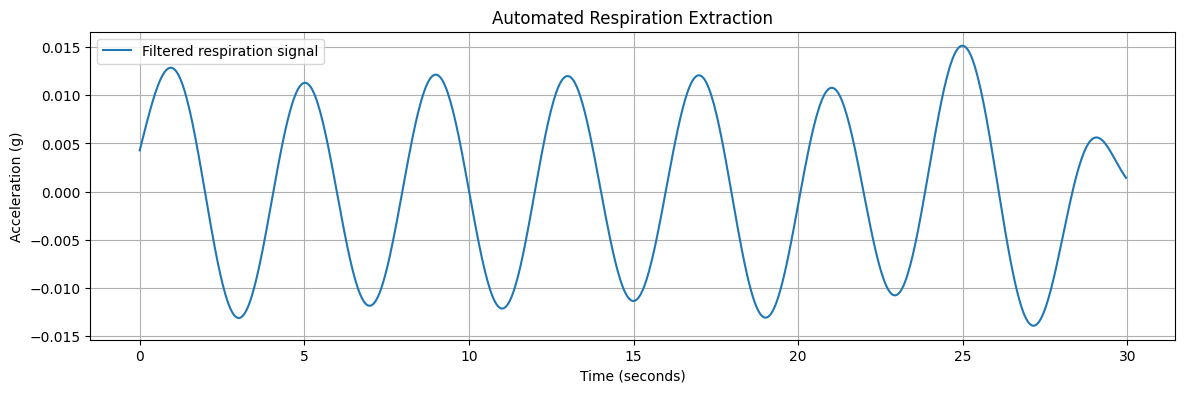

In [31]:
# Heartbeat plot
plt.figure(figsize=(14, 4))

plt.plot(
    results["time"],
    results["heart_signal"],
    label="Filtered heartbeat signal"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Acceleration (g)")
plt.title("Automated Heartbeat Extraction")
plt.legend()
plt.grid()
plt.show()


# Respiration plot
time_resp = np.arange(len(results["resp_signal"])) / (250 / 10)

plt.figure(figsize=(14, 4))

plt.plot(
    time_resp,
    results["resp_signal"],
    label="Filtered respiration signal"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Acceleration (g)")
plt.title("Automated Respiration Extraction")
plt.legend()
plt.grid()
plt.show()

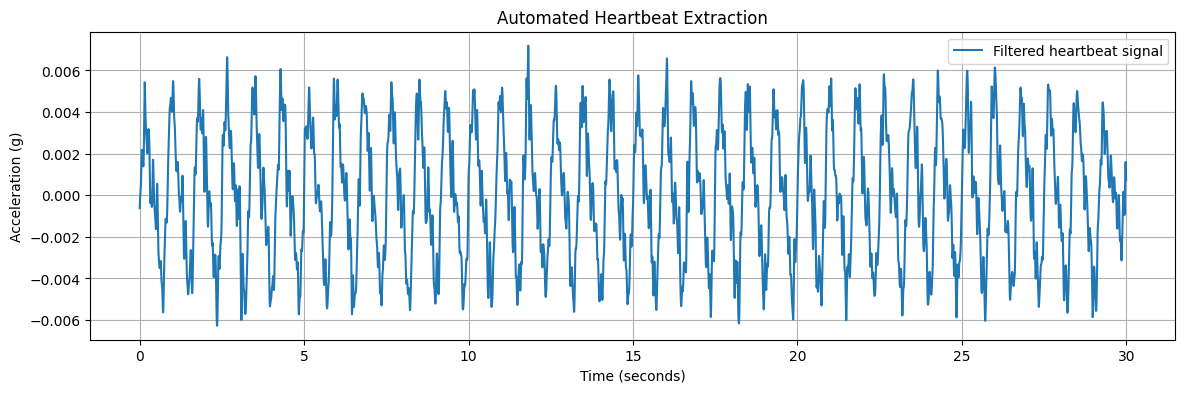

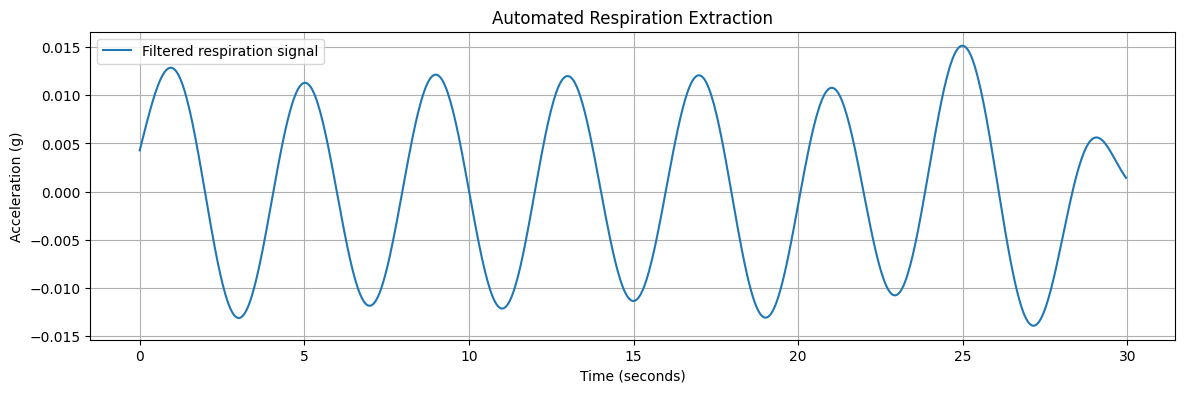

In [ ]:
# Heartbeat plot
plt.figure(figsize=(14, 4))

plt.plot(
    results["time"],
    results["heart_signal"],
    label="Filtered heartbeat signal"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Acceleration (g)")
plt.title("Automated Heartbeat Extraction")
plt.legend()
plt.grid()
plt.show()


# Respiration plot
time_resp = np.arange(len(results["resp_signal"])) / (250 / 10)

plt.figure(figsize=(14, 4))

plt.plot(
    time_resp,
    results["resp_signal"],
    label="Filtered respiration signal"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Acceleration (g)")
plt.title("Automated Respiration Extraction")
plt.legend()
plt.grid()
plt.show()

In [30]:
print("Heart Rate:", results["heart_rate"], "BPM")

print(
    "Respiration Rate:",
    results["respiration_rate"],
    "breaths/min"
)

Heart Rate: 73.71407872494561 BPM
Respiration Rate: 14.999999999999988 breaths/min


In [29]:
print(results.keys())

dict_keys(['heart_rate', 'respiration_rate', 'heart_signal', 'resp_signal', 'heart_peaks', 'resp_peaks', 'time'])


In [28]:
import sys
from pathlib import Path

# Add the src folder to Python's import path
project_root = Path.cwd().parent
sys.path.append(str(project_root / "src"))

# Import the pipeline
from scg_pipeline import process_scg_recording

# Specify the CSV file
csv_path = project_root / "data" / "raw" / "sample_scg.csv"

# Run the complete pipeline
results = process_scg_recording(csv_path)


SCG PROCESSING RESULTS
----------------------
Sampling frequency: 250.0 Hz
Heart Rate: 73.71 BPM
Respiration Rate: 15.0 breaths/min


In [27]:
results.to_csv(
    "../data/processed/hr_rr_results.csv",
    index=False
)

print("Results saved successfully!")

Results saved successfully!


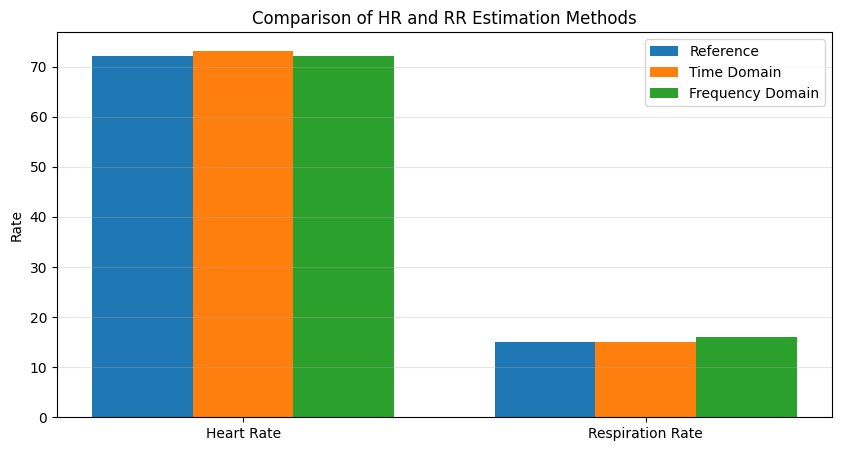

In [26]:
parameters = ["Heart Rate", "Respiration Rate"]

time_values = [hr_time, rr_time]
frequency_values = [hr_frequency, rr_frequency]
reference_values = [reference_hr, reference_rr]

x_pos = np.arange(len(parameters))
width = 0.25

plt.figure(figsize=(10, 5))

plt.bar(
    x_pos - width,
    reference_values,
    width,
    label="Reference"
)

plt.bar(
    x_pos,
    time_values,
    width,
    label="Time Domain"
)

plt.bar(
    x_pos + width,
    frequency_values,
    width,
    label="Frequency Domain"
)

plt.xticks(x_pos, parameters)
plt.ylabel("Rate")
plt.title("Comparison of HR and RR Estimation Methods")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()

In [25]:
# Reference values from the simulated dataset
reference_hr = 72
reference_rr = 15

# Time-domain estimates
hr_time = np.median(valid_hr)
rr_time = estimated_rr

# Frequency-domain estimates
hr_frequency = hr_fft
rr_frequency = rr_fft

# Create comparison table
results = pd.DataFrame({
    "Parameter": ["Heart Rate", "Respiration Rate"],
    "Reference": [reference_hr, reference_rr],
    "Time Domain": [hr_time, rr_time],
    "Frequency Domain": [hr_frequency, rr_frequency]
})

results["Time Domain Error"] = abs(
    results["Time Domain"] - results["Reference"]
)

results["Frequency Domain Error"] = abs(
    results["Frequency Domain"] - results["Reference"]
)

print(results.round(2))

          Parameter  Reference  Time Domain  Frequency Domain  \
0        Heart Rate         72        73.17              72.0   
1  Respiration Rate         15        15.00              16.0   

   Time Domain Error  Frequency Domain Error  
0               1.17                     0.0  
1               0.00                     1.0  


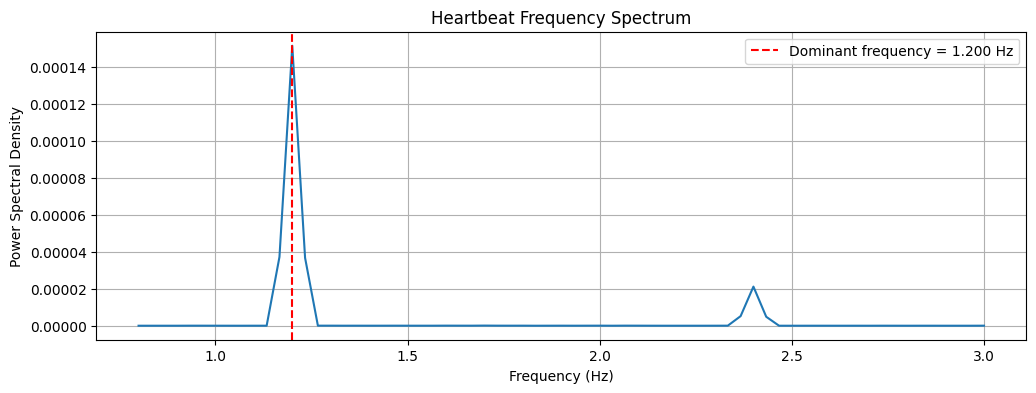

In [24]:
plt.figure(figsize=(12, 4))

plt.plot(heart_freq_range, heart_psd_range)

plt.axvline(
    dominant_heart_freq,
    color="red",
    linestyle="--",
    label=f"Dominant frequency = {dominant_heart_freq:.3f} Hz"
)

plt.xlabel("Frequency (Hz)")
plt.ylabel("Power Spectral Density")
plt.title("Heartbeat Frequency Spectrum")
plt.legend()
plt.grid()
plt.show()

In [23]:
# Calculate PSD of the filtered heartbeat signal
heart_freq, heart_psd = signal.welch(
    heart_signal,
    fs=fs,
    nperseg=len(heart_signal)
)

# Restrict frequency range to plausible heart rates
heart_mask = (heart_freq >= 0.8) & (heart_freq <= 3.0)

heart_freq_range = heart_freq[heart_mask]
heart_psd_range = heart_psd[heart_mask]

# Find dominant frequency
dominant_heart_freq = heart_freq_range[
    np.argmax(heart_psd_range)
]

# Convert frequency to BPM
hr_fft = dominant_heart_freq * 60

print("Dominant cardiac frequency:",
      round(dominant_heart_freq, 3), "Hz")

print("Frequency-domain HR:",
      round(hr_fft, 2), "BPM")

Dominant cardiac frequency: 1.2 Hz
Frequency-domain HR: 72.0 BPM


In [22]:
results = pd.DataFrame({
    "Parameter": [
        "Heart Rate",
        "Respiration Rate"
    ],
    "Time-domain estimate": [
        np.median(valid_hr),
        estimated_rr
    ],
    "Frequency-domain estimate": [
        np.nan,
        rr_fft
    ],
    "Reference value": [
        72,
        15
    ],
    "Unit": [
        "BPM",
        "breaths/min"
    ]
})

print(results.round(2))

          Parameter  Time-domain estimate  Frequency-domain estimate  \
0        Heart Rate                 73.17                        NaN   
1  Respiration Rate                 15.00                       16.0   

   Reference value         Unit  
0               72          BPM  
1               15  breaths/min  


In [21]:
# Compare time-domain and frequency-domain estimates

comparison = pd.DataFrame({
    "Method": [
        "Time-domain peak detection",
        "Frequency-domain Welch PSD"
    ],
    "Estimated RR (breaths/min)": [
        estimated_rr,
        rr_fft
    ]
})

print(comparison.round(2))

                       Method  Estimated RR (breaths/min)
0  Time-domain peak detection                        15.0
1  Frequency-domain Welch PSD                        16.0


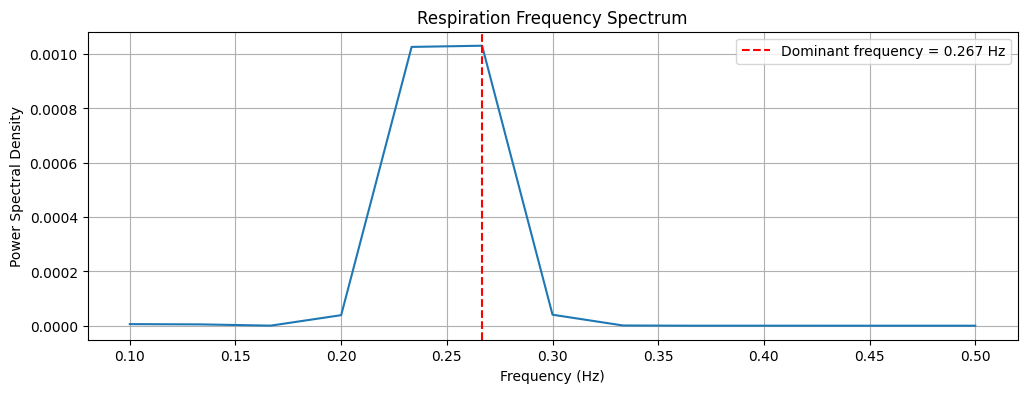

In [20]:
plt.figure(figsize=(12, 4))

plt.plot(resp_frequencies, resp_psd)

plt.axvline(
    dominant_frequency,
    color="red",
    linestyle="--",
    label=f"Dominant frequency = {dominant_frequency:.3f} Hz"
)

plt.xlabel("Frequency (Hz)")
plt.ylabel("Power Spectral Density")
plt.title("Respiration Frequency Spectrum")
plt.legend()
plt.grid()
plt.show()

In [19]:
# Calculate Power Spectral Density using Welch's method
frequencies, psd = signal.welch(
    resp_signal,
    fs=fs_resp,
    nperseg=len(resp_signal)
)

# Restrict analysis to respiration frequency range
mask = (frequencies >= 0.1) & (frequencies <= 0.5)

resp_frequencies = frequencies[mask]
resp_psd = psd[mask]

# Find dominant respiratory frequency
dominant_frequency = resp_frequencies[np.argmax(resp_psd)]

# Convert frequency to breaths per minute
rr_fft = dominant_frequency * 60

print("Dominant respiratory frequency:",
      round(dominant_frequency, 3), "Hz")

print("FFT-based Respiration Rate:",
      round(rr_fft, 2), "breaths/min")

Dominant respiratory frequency: 0.267 Hz
FFT-based Respiration Rate: 16.0 breaths/min


In [18]:
# Calculate intervals between respiratory peaks
resp_intervals = np.diff(resp_peak_times)

# Calculate instantaneous respiration rate
resp_rates = 60 / resp_intervals

# Calculate median respiration rate
estimated_rr = np.median(resp_rates)

print("Estimated Respiration Rate:",
      round(estimated_rr, 2), "breaths/min")

print("Mean Respiration Rate:",
      round(np.mean(resp_rates), 2), "breaths/min")

Estimated Respiration Rate: 15.0 breaths/min
Mean Respiration Rate: 14.96 breaths/min


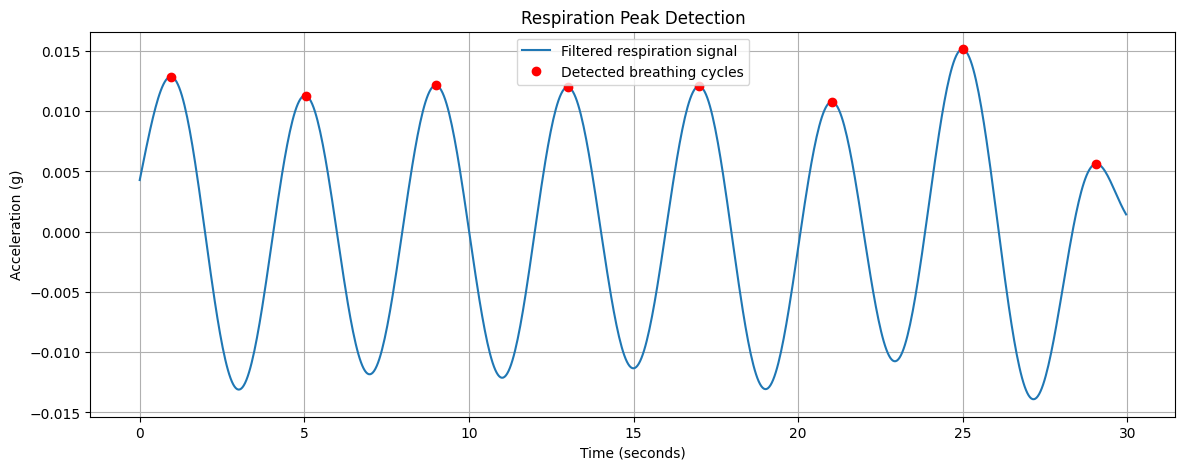

Detected respiratory cycles: 8


In [17]:
# Minimum distance between breaths:
# 30 breaths/min corresponds to 2 seconds per breath
min_resp_distance = int(fs_resp * 60 / 30)

# Detect respiratory peaks
resp_peaks, resp_properties = find_peaks(
    resp_signal,
    distance=min_resp_distance,
    prominence=0.003
)

# Convert peak indices into time
resp_peak_times = time_resp[resp_peaks]

# Plot detected breathing cycles
plt.figure(figsize=(14, 5))

plt.plot(
    time_resp,
    resp_signal,
    label="Filtered respiration signal"
)

plt.plot(
    resp_peak_times,
    resp_signal[resp_peaks],
    "ro",
    label="Detected breathing cycles"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Acceleration (g)")
plt.title("Respiration Peak Detection")
plt.legend()
plt.grid()
plt.show()

print("Detected respiratory cycles:", len(resp_peaks))

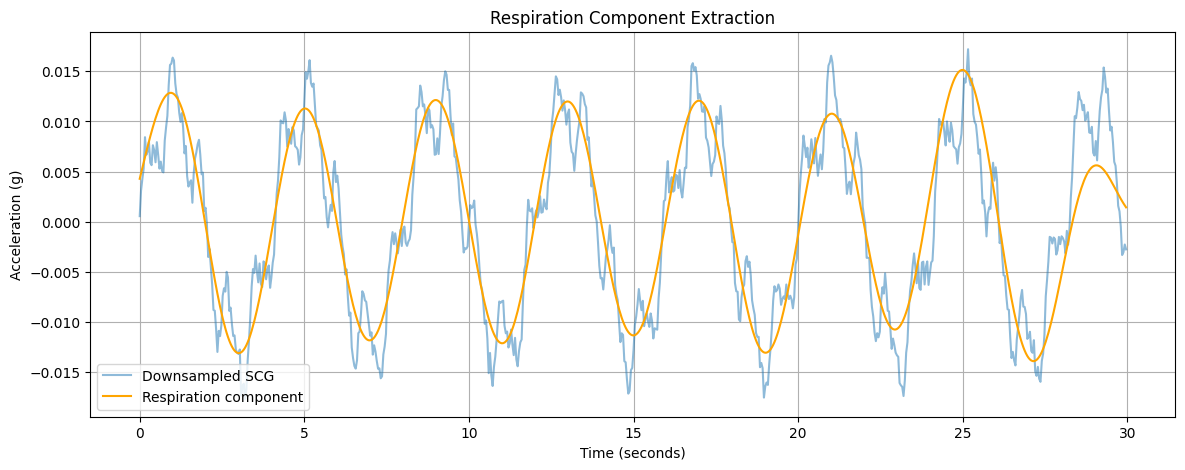

In [16]:
# Design Butterworth respiration bandpass filter
resp_sos = signal.butter(
    N=4,
    Wn=[0.1, 0.5],
    btype="bandpass",
    fs=fs_resp,
    output="sos"
)

# Apply zero-phase filtering
resp_signal = signal.sosfiltfilt(resp_sos, x_resp)

# Plot original and filtered signals
plt.figure(figsize=(14, 5))

plt.plot(
    time_resp,
    x_resp,
    alpha=0.5,
    label="Downsampled SCG"
)

plt.plot(
    time_resp,
    resp_signal,
    color="orange",
    label="Respiration component"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Acceleration (g)")
plt.title("Respiration Component Extraction")
plt.legend()
plt.grid()
plt.show()

In [15]:
# Downsample from 250 Hz to 25 Hz
x_resp = signal.resample_poly(x, up=1, down=10)

# New sampling frequency
fs_resp = 25

# Generate corresponding time array
time_resp = np.arange(len(x_resp)) / fs_resp

print("Original sampling frequency:", fs, "Hz")
print("New sampling frequency:", fs_resp, "Hz")
print("Number of respiration samples:", len(x_resp))

Original sampling frequency: 250 Hz
New sampling frequency: 25 Hz
Number of respiration samples: 750


In [14]:
# Exclude boundary detections
valid_beats = (beat_times >= 1) & (beat_times <= time[-1] - 1)

valid_beat_times = beat_times[valid_beats]

# Recalculate intervals and HR
valid_intervals = np.diff(valid_beat_times)
valid_hr = 60 / valid_intervals

print("Boundary-corrected median HR:",
      round(np.median(valid_hr), 2), "BPM")

Boundary-corrected median HR: 73.17 BPM


In [13]:
# Calculate beat-to-beat intervals
beat_intervals = np.diff(beat_times)

# Calculate instantaneous HR
heart_rates = 60 / beat_intervals

# Summary statistics
print("Number of detected beats:", len(peaks))
print("Median HR:", round(np.median(heart_rates), 2), "BPM")
print("Mean HR:", round(np.mean(heart_rates), 2), "BPM")
print("Minimum HR:", round(np.min(heart_rates), 2), "BPM")
print("Maximum HR:", round(np.max(heart_rates), 2), "BPM")
print("Standard deviation:", round(np.std(heart_rates), 2), "BPM")

Number of detected beats: 37
Median HR: 73.71 BPM
Mean HR: 73.3 BPM
Minimum HR: 60.48 BPM
Maximum HR: 88.76 BPM
Standard deviation: 6.63 BPM


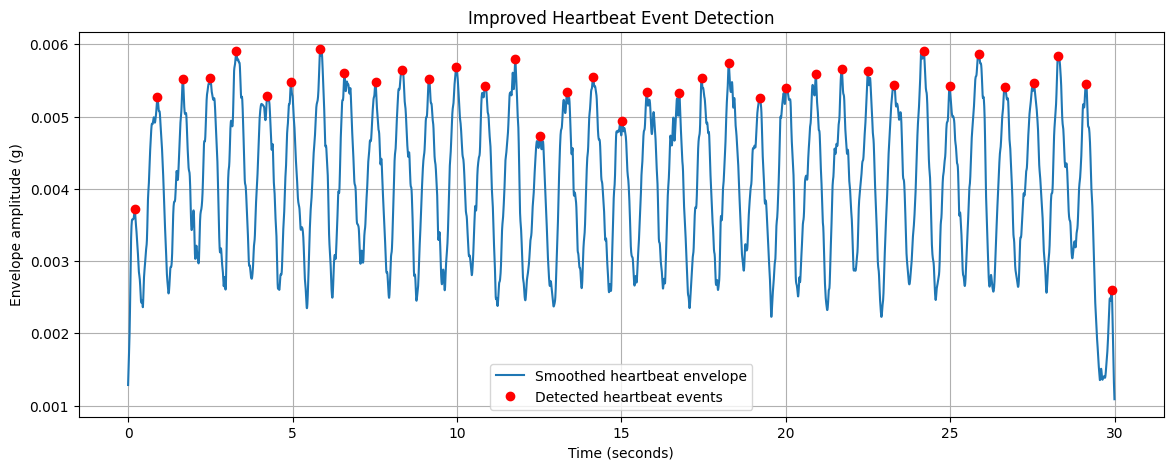

In [12]:
plt.figure(figsize=(14, 5))

plt.plot(time, smoothed_envelope, label="Smoothed heartbeat envelope")

plt.plot(
    beat_times,
    smoothed_envelope[peaks],
    "ro",
    label="Detected heartbeat events"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Envelope amplitude (g)")
plt.title("Improved Heartbeat Event Detection")
plt.legend()
plt.grid()
plt.show()

In [11]:
# Minimum separation: 0.6 seconds
min_distance = int(0.6 * fs)

# Prominence threshold
prominence_threshold = 0.2 * np.std(smoothed_envelope)

# Detect peaks
peaks, properties = find_peaks(
    smoothed_envelope,
    distance=min_distance,
    prominence=prominence_threshold
)

beat_times = time[peaks]

# Calculate intervals and heart rate
beat_intervals = np.diff(beat_times)
heart_rates = 60 / beat_intervals

print("Detected beats:", len(peaks))
print("Median HR:", round(np.median(heart_rates), 2), "BPM")
print("Mean HR:", round(np.mean(heart_rates), 2), "BPM")

Detected beats: 37
Median HR: 73.71 BPM
Mean HR: 73.3 BPM


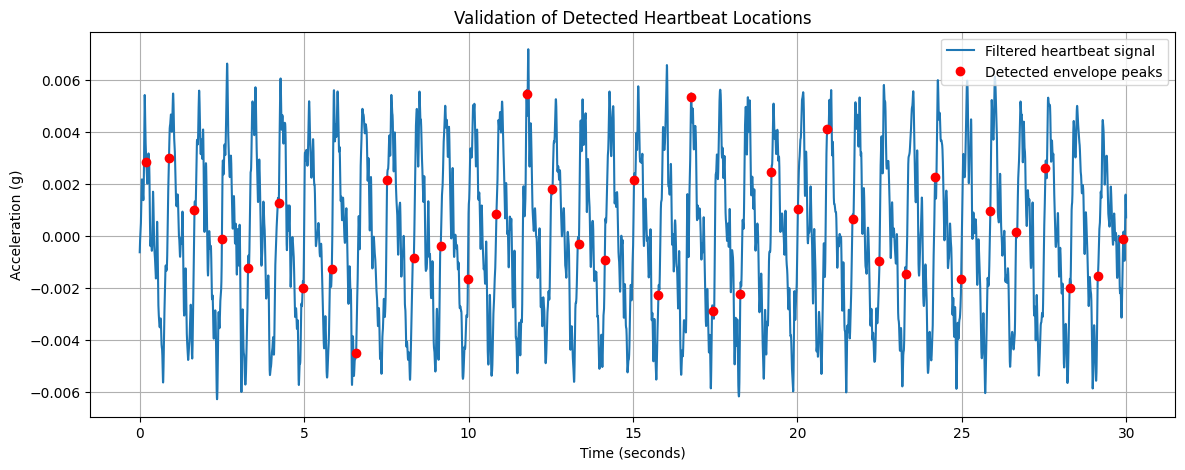

In [10]:
plt.figure(figsize=(14, 5))

plt.plot(time, heart_signal, label="Filtered heartbeat signal")
plt.plot(
    beat_times,
    heart_signal[peaks],
    "ro",
    label="Detected envelope peaks"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Acceleration (g)")
plt.title("Validation of Detected Heartbeat Locations")
plt.legend()
plt.grid()
plt.show()

In [9]:
print("Detected beats:", len(peaks))
print("Median HR:", round(np.median(heart_rates), 2), "BPM")
print("Mean HR:", round(np.mean(heart_rates), 2), "BPM")
print("Minimum HR:", round(np.min(heart_rates), 2), "BPM")
print("Maximum HR:", round(np.max(heart_rates), 2), "BPM")

print("\nBeat intervals:")
print(np.round(beat_intervals, 3))

Detected beats: 37
Median HR: 73.71 BPM
Mean HR: 73.3 BPM
Minimum HR: 60.48 BPM
Maximum HR: 88.76 BPM

Beat intervals:
[0.692 0.772 0.836 0.792 0.936 0.724 0.888 0.74  0.944 0.808 0.82  0.828
 0.868 0.924 0.756 0.82  0.792 0.892 0.74  0.992 0.676 0.824 0.948 0.804
 0.896 0.788 0.796 0.808 0.888 0.788 0.888 0.788 0.888 0.732 0.86  0.772]


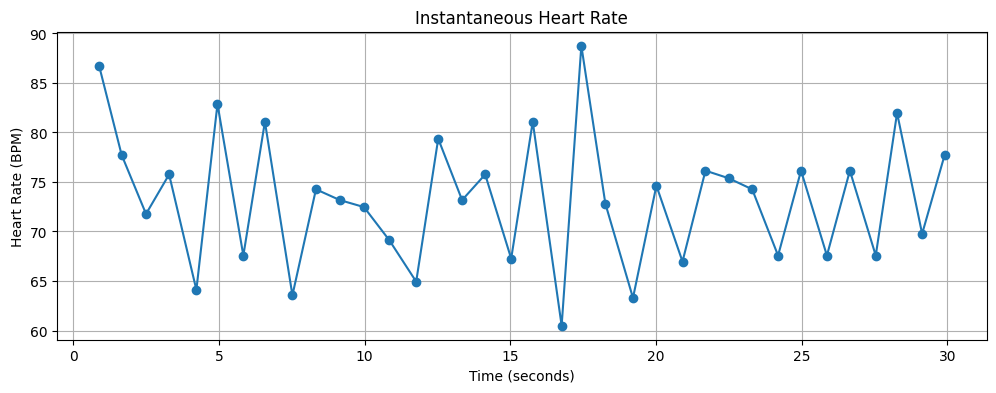

In [8]:
plt.figure(figsize=(12, 4))

plt.plot(beat_times[1:], heart_rates, marker="o")

plt.xlabel("Time (seconds)")
plt.ylabel("Heart Rate (BPM)")
plt.title("Instantaneous Heart Rate")
plt.grid()
plt.show()

In [7]:
# Convert peak indices into time values
beat_times = time[peaks]

# Calculate intervals between consecutive beats
beat_intervals = np.diff(beat_times)

# Calculate instantaneous heart rate
heart_rates = 60 / beat_intervals

# Calculate median heart rate
estimated_hr = np.median(heart_rates)

print("Estimated Heart Rate:", round(estimated_hr, 2), "BPM")
print("Number of beat intervals:", len(heart_rates))

Estimated Heart Rate: 73.71 BPM
Number of beat intervals: 36


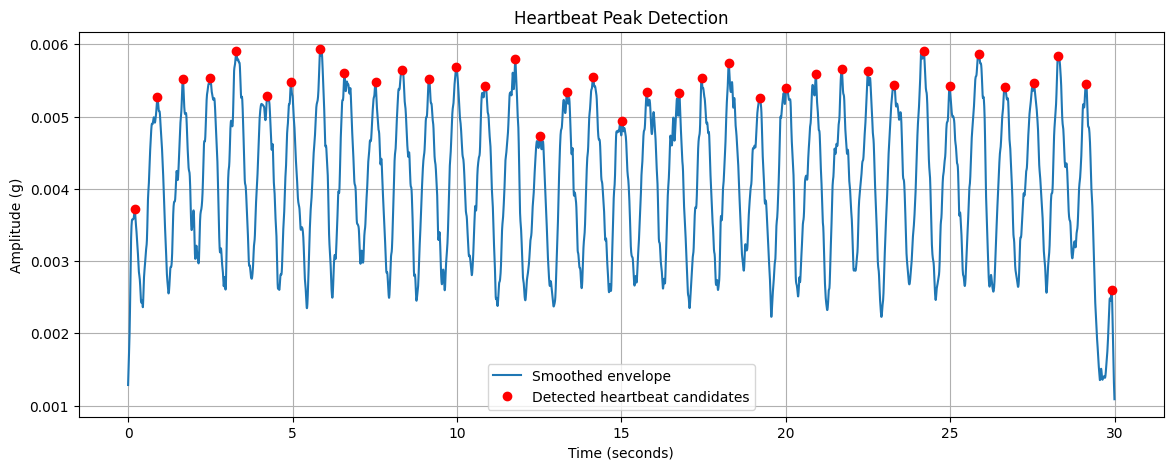

Number of detected peaks: 37


In [6]:
# Minimum distance between peaks:
# 180 BPM corresponds to 0.333 seconds between beats
min_distance = int(fs * 60 / 180)

# Set an initial prominence threshold
prominence_threshold = 0.25 * np.std(smoothed_envelope)

# Detect peaks
peaks, properties = find_peaks(
    smoothed_envelope,
    distance=min_distance,
    prominence=prominence_threshold
)

# Plot detected peaks
plt.figure(figsize=(14, 5))

plt.plot(time, smoothed_envelope, label="Smoothed envelope")
plt.plot(
    time[peaks],
    smoothed_envelope[peaks],
    "ro",
    label="Detected heartbeat candidates"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (g)")
plt.title("Heartbeat Peak Detection")
plt.legend()
plt.grid()
plt.show()

print("Number of detected peaks:", len(peaks))

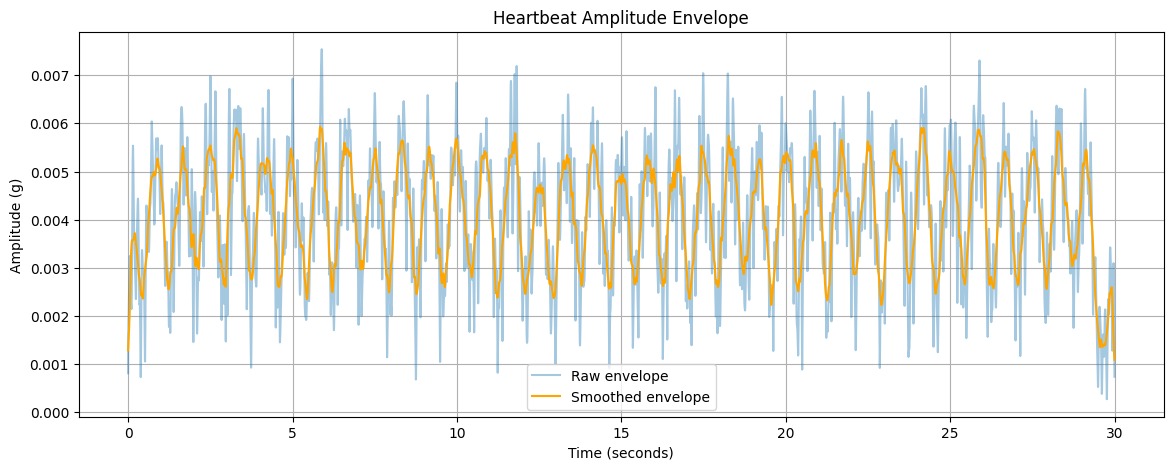

In [5]:
# Calculate the analytic signal using Hilbert transform
analytic_signal = signal.hilbert(heart_signal)

# Extract amplitude envelope
heart_envelope = np.abs(analytic_signal)

# Smooth the envelope using a moving average
window_size = int(0.15 * fs)  # 150 ms

smoothed_envelope = np.convolve(
    heart_envelope,
    np.ones(window_size) / window_size,
    mode="same"
)

# Plot both envelopes
plt.figure(figsize=(14, 5))

plt.plot(
    time,
    heart_envelope,
    alpha=0.4,
    label="Raw envelope"
)

plt.plot(
    time,
    smoothed_envelope,
    color="orange",
    label="Smoothed envelope"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (g)")
plt.title("Heartbeat Amplitude Envelope")
plt.legend()
plt.grid()
plt.show()

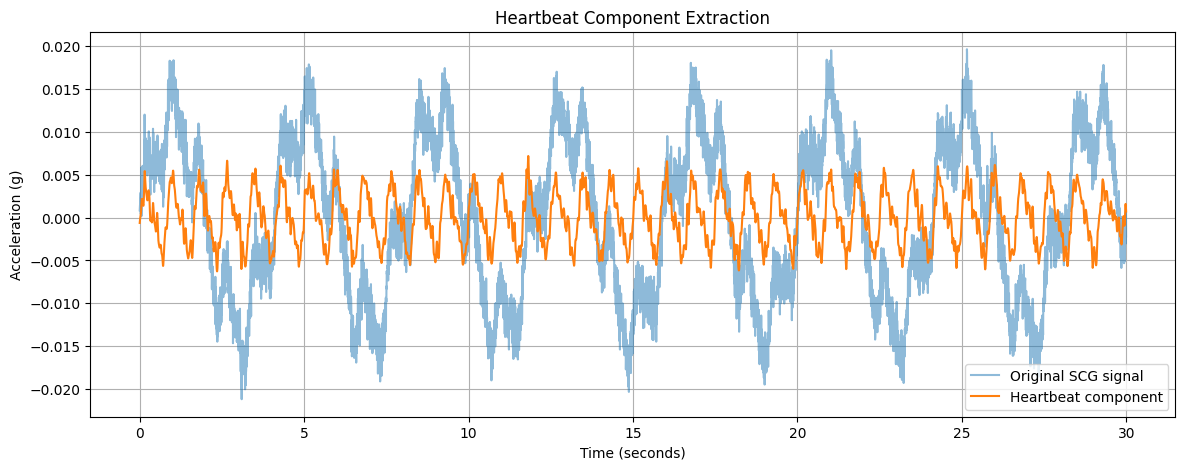

In [4]:
# Design a Butterworth bandpass filter
heart_sos = signal.butter(
    N=4,
    Wn=[0.8, 20],
    btype="bandpass",
    fs=fs,
    output="sos"
)

# Apply zero-phase filtering
heart_signal = signal.sosfiltfilt(heart_sos, x)

# Plot original and filtered signals
plt.figure(figsize=(14, 5))

plt.plot(time, x, alpha=0.5, label="Original SCG signal")
plt.plot(time, heart_signal, label="Heartbeat component")

plt.xlabel("Time (seconds)")
plt.ylabel("Acceleration (g)")
plt.title("Heartbeat Component Extraction")
plt.legend()
plt.grid()
plt.show()

In [2]:
print(df.columns.tolist())

['sample_index', 'timestamp_ms', 'ax_raw', 'ay_raw', 'az_raw', 'esp32_hr_bpm', 'esp32_rr_bpm', 'ax_g', 'ay_g', 'az_g', 'ax_g_clean', 'ay_g_clean', 'az_g_clean']


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import signal
from scipy.signal import find_peaks

# Load processed data
df = pd.read_csv("../data/processed/scg_processed.csv")

# Sampling frequency
fs = 250

# Generate time array in seconds
time = (df["timestamp_ms"] - df["timestamp_ms"].iloc[0]).to_numpy() / 1000

# Load cleaned SCG signal
x = df["az_g_clean"].to_numpy()

print("Sampling frequency:", fs, "Hz")
print("Number of samples:", len(x))
print("Duration:", round(time[-1], 2), "seconds")
print("Missing values:", np.isnan(x).sum())

Sampling frequency: 250 Hz
Number of samples: 7500
Duration: 30.0 seconds
Missing values: 0
